# Baseline evaluation across introduction years

## Summary

This notebook adds temporal cross-validation and error examples to the existing
classification baselines. It reuses the models, features and TF-IDF settings
from [notebook 05](05_classification_baselines.ipynb).

The expanding-year folds use only 2019–2024 records. The 2025 cohort remains a
separate validation diagnostic. No 2026 records are fitted or scored here.

Across these three folds, XGBoost with bill text has the highest mean macro F1
(0.4567, sample SD 0.2586), compared with 0.1950 for the majority reference.
The existing SVM bill-text baseline scores 0.5659 on the separate 2025 cohort,
but recovers only 44 of its 185 recorded Passed bills. Model rankings and class
balance vary by year; these results do not select a final model.


## Methods

Each fold trains on earlier introduction years and validates on the next year:
2019–2021 → 2022, 2019–2022 → 2023, and 2019–2023 → 2024. All nine configurations
use the same rows. Preprocessing and XGBoost label encoding are fitted within
each training fold through `run_experiment`.

Macro F1 gives equal weight to **Failed, Passed and Pending**, including a zero
when a class is not recovered. A most-frequent classifier provides a simple
reference. Means weight the three folds equally; sample standard deviations
show variation across years, not confidence intervals.

### Limits

The early folds are small, particularly the 33-record 2022 validation cohort.
Class proportions and the time available for a bill to resolve also change
across years. Recorded text and sponsor information may reflect later bill
stages. These checks evaluate classification of recorded statuses, not a
prediction made when a bill was introduced. Related bill texts may cross folds;
introduction-year separation does not establish independence.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(root))
import src.classification_helpers as ch
from src.topic_analysis import LEGAL_STOPWORDS

plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})
output_dir = root / "data/processed/model_evaluation"
output_dir.mkdir(parents=True, exist_ok=True)
LABELS = ["Failed", "Passed", "Pending"]
TARGET = "Bill_Status_Grouped"

## Data and baseline settings

The input is the prepared table generated by `python src/prepare.py`, from the
[published corpus, version 4](https://zenodo.org/records/20781731).
`source_row` identifies the original CSV record. Source outcomes are unchanged.
The feature groups below match notebook 05; no topic features or tuning are added.

In [2]:
common = pd.read_csv(root / "data/processed/common_intake/common_records.csv")
common["introduction_year"] = pd.to_datetime(
    common["Introduction_Date"], errors="coerce"
).dt.year
training = common[common["introduction_year"].between(2019, 2024)].copy()
validation = common[common["introduction_year"] == 2025].copy()

FEATURE_GROUPS = {
    "categorical": ["measure_code", "Jurisdiction", "State_Political_Control"],
    "numeric": ["D_Count", "R_Count", "Other_Count", "Unknown_Count", "Total_Sponsors"],
    "ratio": ["Democrat_Sponsor_Ratio", "Republican_Sponsor_Ratio"],
    "binary": ["Bipartisan_Support"],
}
FEATURE_SETS = {
    "metadata": None,
    "summary": "NCSL_Summary_clean",
    "bill_text": "Bill_Text_clean",
}
TFIDF_PARAMS = {
    "max_features": 5000, "ngram_range": (1, 2), "min_df": 2,
    "max_df": 0.95, "sublinear_tf": True,
    "stop_words": sorted(LEGAL_STOPWORDS.keys()),
}
MODELS = ["logistic_regression", "linear_svm", "xgboost"]
MODEL_NAMES = {"logistic_regression": "Logistic regression",
               "linear_svm": "Linear SVM", "xgboost": "XGBoost"}
INPUT_NAMES = {"metadata": "Metadata", "summary": "Metadata + summary",
               "bill_text": "Metadata + bill text"}

display(pd.DataFrame({
    "Training: 2019–2024": training[TARGET].value_counts(),
    "Validation: 2025": validation[TARGET].value_counts(),
}).reindex(LABELS).fillna(0).astype(int))

,Training: 2019–2024,Validation: 2025
Bill_Status_Grouped,,
Failed,327,281
Passed,96,185
Pending,299,550


### Fold sizes and class counts

Each row below describes one training or validation cohort. Counts refer to
prepared source records, not independently verified unique bills.

In [3]:
folds = []
cohort_counts = []
for year in [2022, 2023, 2024]:
    fold_train = training[training["introduction_year"] < year].copy()
    fold_validation = training[training["introduction_year"] == year].copy()
    folds.append((year, fold_train, fold_validation))
    for split, frame in [("Train", fold_train), ("Validate", fold_validation)]:
        counts = frame[TARGET].value_counts().reindex(LABELS, fill_value=0)
        cohort_counts.append({"Validation year": year, "Split": split,
                              "Records": len(frame), **counts.to_dict()})
fold_counts = pd.DataFrame(cohort_counts)
display(fold_counts)
fold_counts.to_csv(output_dir / "fold_class_counts.csv", index=False)

,Validation year,Split,Records,Failed,Passed,Pending
0,2022,Train,129,89,24,16
1,2022,Validate,33,25,4,4
2,2023,Train,162,114,28,20
3,2023,Validate,90,16,6,68
4,2024,Train,252,130,34,88
5,2024,Validate,470,197,62,211


## Temporal cross-validation

Every run starts with a fresh pipeline. Imputation, scaling, one-hot encoding
and the text vocabulary learn only from that fold's training records. Model
settings remain unchanged so this is a baseline robustness check, not tuning.

In [4]:
fold_results = []
for year, fold_train, fold_validation in folds:
    dummy = DummyClassifier(strategy="most_frequent")
    dummy.fit(np.zeros((len(fold_train), 1)), fold_train[TARGET])
    dummy_predictions = dummy.predict(np.zeros((len(fold_validation), 1)))
    fold_results.append({
        "Model": "most_frequent", "Input": "metadata", "Validation year": year,
        "Train records": len(fold_train), "Validation records": len(fold_validation),
        "Macro F1": f1_score(fold_validation[TARGET], dummy_predictions,
                             labels=LABELS, average="macro", zero_division=0),
    })
    for model in MODELS:
        for feature_set in FEATURE_SETS:
            run = ch.run_experiment(
                model_type=model, feature_set=feature_set,
                train_df=fold_train, val_df=fold_validation, target=TARGET,
                feature_groups=FEATURE_GROUPS, feature_sets=FEATURE_SETS,
                tfidf_params=TFIDF_PARAMS,
            )
            fold_results.append({
                "Model": model, "Input": feature_set, "Validation year": year,
                "Train records": len(fold_train),
                "Validation records": len(fold_validation),
                "Macro F1": f1_score(run["y_val"], run["val_predictions"],
                                     labels=LABELS, average="macro", zero_division=0),
            })
    print(f"Completed validation year {year}.")

fold_results = pd.DataFrame(fold_results)
cv_summary = (fold_results.groupby(["Model", "Input"], sort=False)["Macro F1"]
              .agg(Mean="mean", SD="std", Folds="count").reset_index())
fold_results.to_csv(output_dir / "cv_fold_scores.csv", index=False)
cv_summary.to_csv(output_dir / "cv_summary.csv", index=False)
display(cv_summary.round(4))

Completed validation year 2022.


Completed validation year 2023.


Completed validation year 2024.


,Model,Input,Mean,SD,Folds
0,most_frequent,metadata,0.1950,0.0934,3
1,logistic_regression,metadata,0.3651,0.1940,3
2,logistic_regression,summary,0.3419,0.2357,3
3,logistic_regression,bill_text,0.4026,0.2197,3
4,linear_svm,metadata,0.4048,0.2058,3
5,linear_svm,summary,0.3738,0.2242,3
6,linear_svm,bill_text,0.3991,0.2518,3
7,xgboost,metadata,0.2880,0.1778,3
8,xgboost,summary,0.3210,0.2090,3
9,xgboost,bill_text,0.4567,0.2586,3


### Compare the same configurations across years

Dots show the mean of three folds; horizontal bars show one sample standard
deviation. Faint crosses show individual fold scores. The dashed line is the
mean most-frequent reference. These are equal-weight yearly comparisons, not a
pooled score or a statistical significance test.

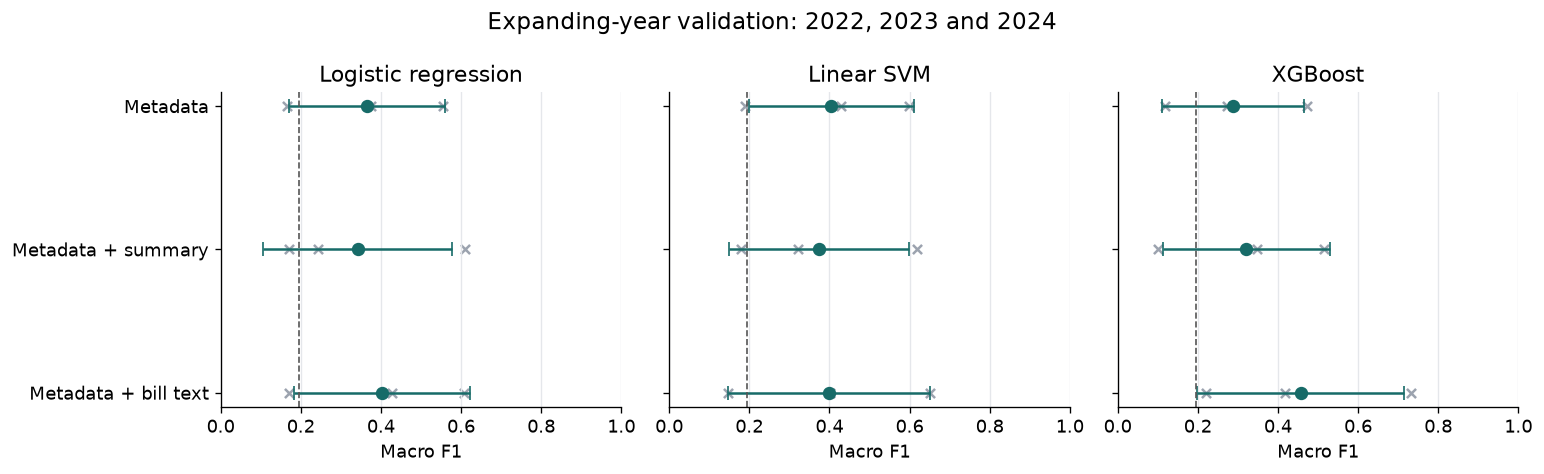

In [5]:
dummy_mean = cv_summary.loc[cv_summary["Model"] == "most_frequent", "Mean"].iloc[0]
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, model in zip(axes, MODELS):
    values = cv_summary[cv_summary["Model"] == model].set_index("Input")
    for position, feature_set in enumerate(FEATURE_SETS):
        scores = fold_results.loc[
            (fold_results["Model"] == model) & (fold_results["Input"] == feature_set),
            "Macro F1",
        ]
        ax.scatter(scores, [position] * len(scores), marker="x", color="#9CA3AF", s=30)
        ax.errorbar(values.loc[feature_set, "Mean"], position,
                    xerr=values.loc[feature_set, "SD"], fmt="o", capsize=4,
                    color="#176B68", markersize=7)
    ax.axvline(dummy_mean, color="#555555", linestyle="--", linewidth=1)
    ax.set_title(MODEL_NAMES[model])
    ax.set_xlabel("Macro F1")
    ax.set_xlim(0, 1)
    ax.grid(axis="x", color="#E5E7EB")
axes[0].set_yticks(range(3), [INPUT_NAMES[key] for key in FEATURE_SETS])
axes[0].invert_yaxis()
fig.suptitle("Expanding-year validation: 2022, 2023 and 2024", fontsize=14)
fig.tight_layout()
fig.savefig(output_dir / "temporal_cv_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 2025 validation diagnostic

Notebook 05's strongest saved validation baseline is Linear SVM with metadata
and bill text. The following run reproduces that configuration on 2019–2024
training records and evaluates 2025. This is not a final test score, and the
model was already compared on this validation cohort. No 2026 evaluation is
performed. The results below retain the three recorded outcome groups.

In [6]:
svm_run = ch.run_experiment(
    model_type="linear_svm", feature_set="bill_text",
    train_df=training, val_df=validation, target=TARGET,
    feature_groups=FEATURE_GROUPS, feature_sets=FEATURE_SETS,
    tfidf_params=TFIDF_PARAMS,
)
validation_report = pd.DataFrame(classification_report(
    svm_run["y_val"], svm_run["val_predictions"], labels=LABELS,
    output_dict=True, zero_division=0,
)).T.drop(index="accuracy")
validation_report.to_csv(output_dir / "svm_2025_classification_report.csv")
display(validation_report.round(4))
print(f"Training macro F1: {f1_score(svm_run['y_train'], svm_run['train_predictions'], labels=LABELS, average='macro'):.4f}")

validation_dummy = DummyClassifier(strategy="most_frequent")
validation_dummy.fit(np.zeros((len(training), 1)), training[TARGET])
dummy_predictions = validation_dummy.predict(np.zeros((len(validation), 1)))
dummy_f1 = f1_score(validation[TARGET], dummy_predictions, labels=LABELS,
                    average="macro", zero_division=0)
print(f"2025 majority-reference macro F1: {dummy_f1:.4f}")


,precision,recall,f1-score,support
Failed,0.4509,0.8505,0.5894,281.0
Passed,0.4835,0.2378,0.3188,185.0
Pending,0.9443,0.6782,0.7894,550.0
macro avg,0.6263,0.5889,0.5659,1016.0
weighted avg,0.7239,0.6457,0.6484,1016.0


Training macro F1: 0.9657
2025 majority-reference macro F1: 0.1444


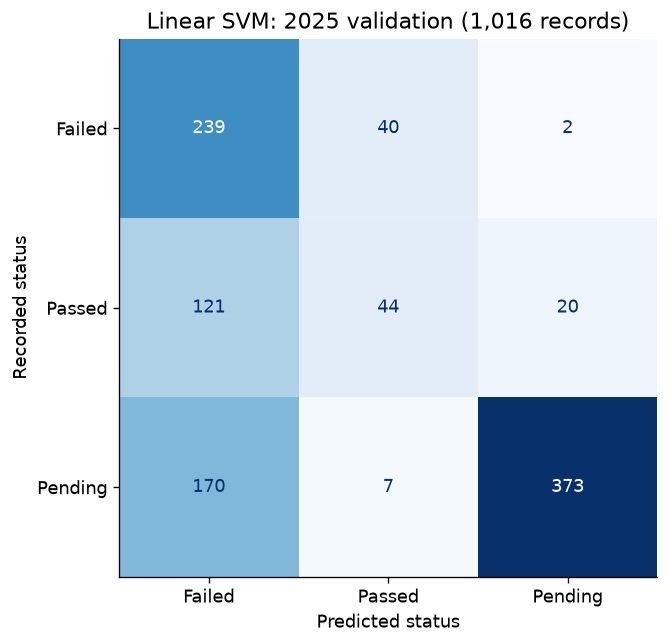

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(
    svm_run["y_val"], svm_run["val_predictions"], labels=LABELS,
    display_labels=LABELS, cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title(f"Linear SVM: 2025 validation ({len(validation):,} records)")
ax.set_xlabel("Predicted status")
ax.set_ylabel("Recorded status")
fig.tight_layout()
fig.savefig(output_dir / "svm_2025_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

### Three prediction errors

Select the first record in source order for three distinct recorded-to-predicted
error pairs, where available. This deterministic selection illustrates different
errors; it is not a representative sample. Excerpts provide context, not proof
of why the classifier made a decision. The full source text may postdate bill
introduction, and linked source pages may change.

In [8]:
predictions = validation[["source_row", "Jurisdiction", "Bill_Number", "Introduction_Date",
                          "Bill_Title", "Bill_URL", "Bill_Text_clean", TARGET]].copy()
predictions = predictions.rename(columns={TARGET: "Recorded status"})
predictions["Predicted status"] = svm_run["val_predictions"]
predictions.drop(columns="Bill_Text_clean").to_csv(
    output_dir / "svm_2025_predictions.csv", index=False
)
errors = predictions[predictions["Recorded status"] != predictions["Predicted status"]]
examples = (errors.sort_values(["Recorded status", "Predicted status", "source_row"])
            .drop_duplicates(["Recorded status", "Predicted status"]).head(3))
examples = examples.assign(Excerpt=examples["Bill_Text_clean"].str.slice(0, 500))
examples.drop(columns="Bill_Text_clean").to_csv(output_dir / "prediction_error_examples.csv", index=False)
display(examples[["source_row", "Jurisdiction", "Bill_Number", "Introduction_Date", "Recorded status",
                  "Predicted status", "Bill_Title"]])
for row in examples.to_dict("records"):
    print(f"\nSource row {row['source_row']}: {row['Jurisdiction']} {row['Bill_Number']}")
    print(f"Recorded {row['Recorded status']}; predicted {row['Predicted status']}")
    print(f"Text excerpt: {row['Excerpt']}…")
    print(f"Source: {row['Bill_URL']}")

,source_row,Jurisdiction,Bill_Number,Introduction_Date,Recorded status,Predicted status,Bill_Title
3,4,Alabama,H 516,04/03/2025,Failed,Passed,Consumer Protection
827,832,Virginia,S 1417,01/16/2025,Failed,Pending,Digital Content Authenticity and Transparency Act
10,11,Arizona,H 2175,01/14/2025,Passed,Failed,Claims and Prior Authorization



Source row 4: Alabama H 516
Recorded Failed; predicted Passed
Text excerpt: HB516 INTRODUCED ENNJ229-1 By Representatives Chestnut, Shaw, Lipscomb, Moore (P), Gray, Robbins, Rigsby RFD: Commerce and Small Business First Read: 03-Apr-25 SYNOPSIS: Under existing law, the Legislature has declared numerous deceptive acts or practices in the conduct of any trade or commerce to be unlawful. This bill would further provide that the use of a computer to interact with a consumer as part of a commercial transaction in a manner that would deceive the consumer into reasonably belie…
Source: https://sn.lexisnexis.com/opentext/eyJ0eXBlIjoiYmlsbCIsImlkIjoiQUwyMDI1MDAwSDUxNiJ9.pd4KgAyVRbT9j8M04IVxGaAWKtP6GrdFyEfgDQ7SDgI

Source row 832: Virginia S 1417
Recorded Failed; predicted Pending
Text excerpt: SENATE BILL NO. 1417 Offered January 16, 2025 A BILL to amend the Code of Virginia by adding in Title 59.1 a chapter numbered 58, consisting of sections numbered 59.1-607 through 59.1-610, relating to Di

### What the examples show

- **Alabama H 516, source row 4:** Failed was predicted as Passed. The
  excerpt describes a proposed consumer-protection change, not its procedural
  outcome. Comparing this bill's feature contributions with correctly classified
  bills could help explain the false positive; subject matter alone is not an
  outcome label.
- **Virginia S 1417, source row 832:** Failed was predicted as Pending. The
  offered-bill text includes the standard phrase “Be it enacted,” which is not
  proof that the bill became law. A dated outcome rule and a review of procedural
  text would help distinguish unresolved bills from terminal failures.
- **Arizona H 2175, source row 11:** Passed was predicted as Failed. Its
  source text includes “CHAPTER 165,” so a later-stage header does not guarantee
  a correct prediction. Test class weighting and header/body sensitivity before
  attributing the error to any particular phrase.

These are observed error directions and proposed checks, not established causes.
The broader concern is missed Passed records: 121 were classified as Failed and
20 as Pending. The failure review does not authorize changing source labels.


## Takeaways

The model ranking changes between the historical folds and the existing 2025
validation comparison. XGBoost with bill text has the highest historical mean,
with substantial spread. SVM remains the strongest saved 2025 baseline. Do not
discard either family based on a single year's score.

The SVM confusion matrix shows that 141 of 185 Passed records are missed.
Class-weight sensitivity and feature ablations are useful next checks. The
three cases above connect errors to inspectable records without claiming
that an excerpt explains the model's decision.

These are baseline comparisons, not tuned best models from each family.
Hyperparameter exploration, best-model importance/ablation, the topic-feature
experiment and an agreed final test evaluation remain. The 2026 cohort stays
untouched. Tables and figures are saved under `data/processed/model_evaluation/`.
